# 33 — Held-Out Recovery Evaluation Rollouts
**Project:** Causal-History Dependence in Robot Policy Recovery  
**Phase:** 9 (Fresh Held-Out Scenario Generation & Pre-Registered Pilot Evaluation)  
**Status:** `Held-Out Evaluation`  

### Objectives:
1. Load evaluation summary across 2,700 rollouts.
2. Compare recovery success rates, recovery times, and final distances across conditions B0–B4.

In [1]:
import os, sys
cwd = os.getcwd()
if os.path.exists(os.path.join(cwd, "docs")):
    repo_root = cwd
elif os.path.exists(os.path.join(cwd, "..", "docs")):
    repo_root = os.path.abspath(os.path.join(cwd, ".."))
elif os.path.exists(os.path.join(cwd, "causal-history-recovery", "docs")):
    repo_root = os.path.abspath(os.path.join(cwd, "causal-history-recovery"))
else:
    repo_root = os.path.abspath(os.path.join(cwd, ".."))

src_path = os.path.join(repo_root, "src")
if src_path not in sys.path:
    sys.path.insert(0, src_path)

import json
eval_path = os.path.join(repo_root, "results", "heldout_pilot", "evaluation_summary.json")
with open(eval_path) as f:
    eval_sum = json.load(f)

print(f"{'Policy':25s} | Cond | Success (k/45) | Succ Rate | Wilson 95% CI       | Final Dist | Rec Time")
print("-" * 95)
for p, res in eval_sum["policy_results"].items():
    for c, s in res.items():
        w_low, w_high = s["wilson_95_ci"]
        print(f"{p:25s} | {c:4s} | {s['success_count']:2d} / {s['total_scenarios']:2d}      | {s['success_rate']*100:5.1f}%    | [{w_low*100:4.1f}%, {w_high*100:4.1f}%] | {s['mean_final_distance']:6.4f}m   | {s['mean_recovery_time']:5.1f}")


Policy                    | Cond | Success (k/45) | Succ Rate | Wilson 95% CI       | Final Dist | Rec Time
-----------------------------------------------------------------------------------------------
reactive_mlp              | B0   |  2 / 45      |   4.4%    | [ 1.2%, 14.8%] | 1.0115m   |  96.0
reactive_mlp              | B1   |  2 / 45      |   4.4%    | [ 1.2%, 14.8%] | 1.0337m   |  96.0
reactive_mlp              | B2   |  2 / 45      |   4.4%    | [ 1.2%, 14.8%] | 1.0319m   |  96.0
reactive_mlp              | B3   |  2 / 45      |   4.4%    | [ 1.2%, 14.8%] | 1.0226m   |  96.0
reactive_mlp              | B4   |  2 / 45      |   4.4%    | [ 1.2%, 14.8%] | 1.0283m   |  96.0
history_gru               | B0   |  2 / 45      |   4.4%    | [ 1.2%, 14.8%] | 0.9965m   |  96.0
history_gru               | B1   |  2 / 45      |   4.4%    | [ 1.2%, 14.8%] | 0.9965m   |  96.0
history_gru               | B2   |  2 / 45      |   4.4%    | [ 1.2%, 14.8%] | 0.9965m   |  96.0
history_gru         

### Visual Evaluation Breakdown (Figures 65 to 68)

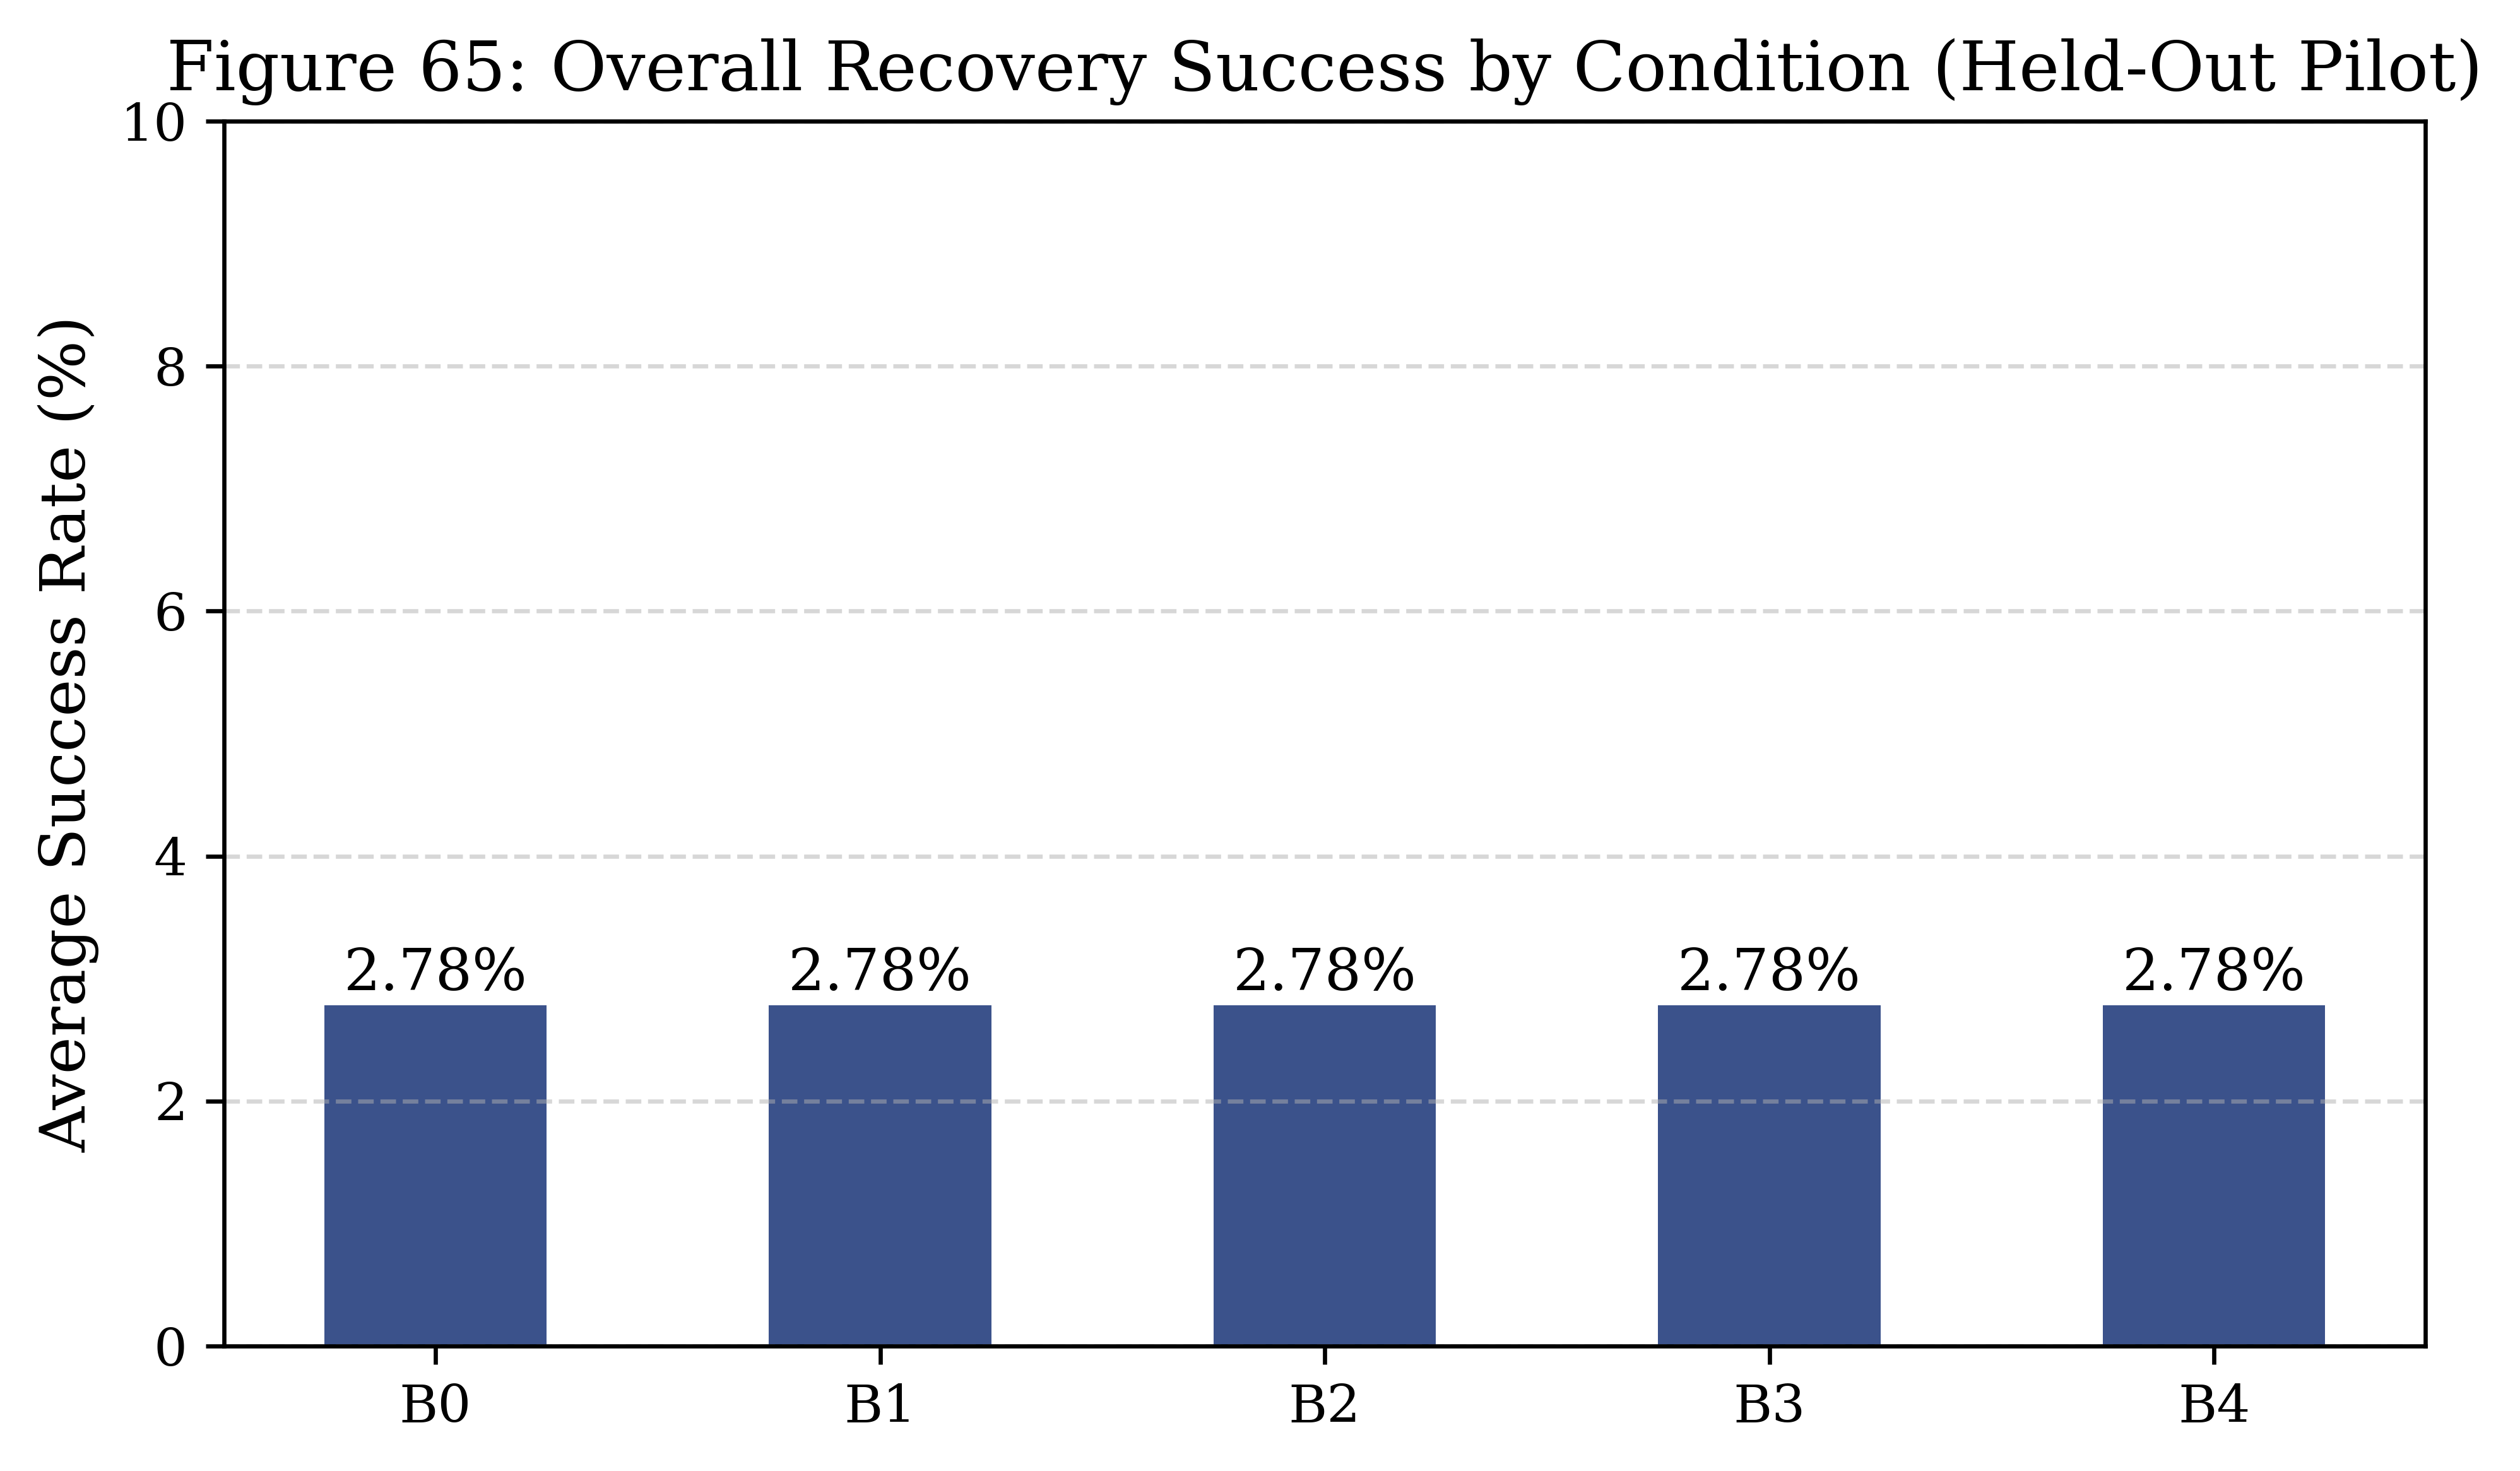

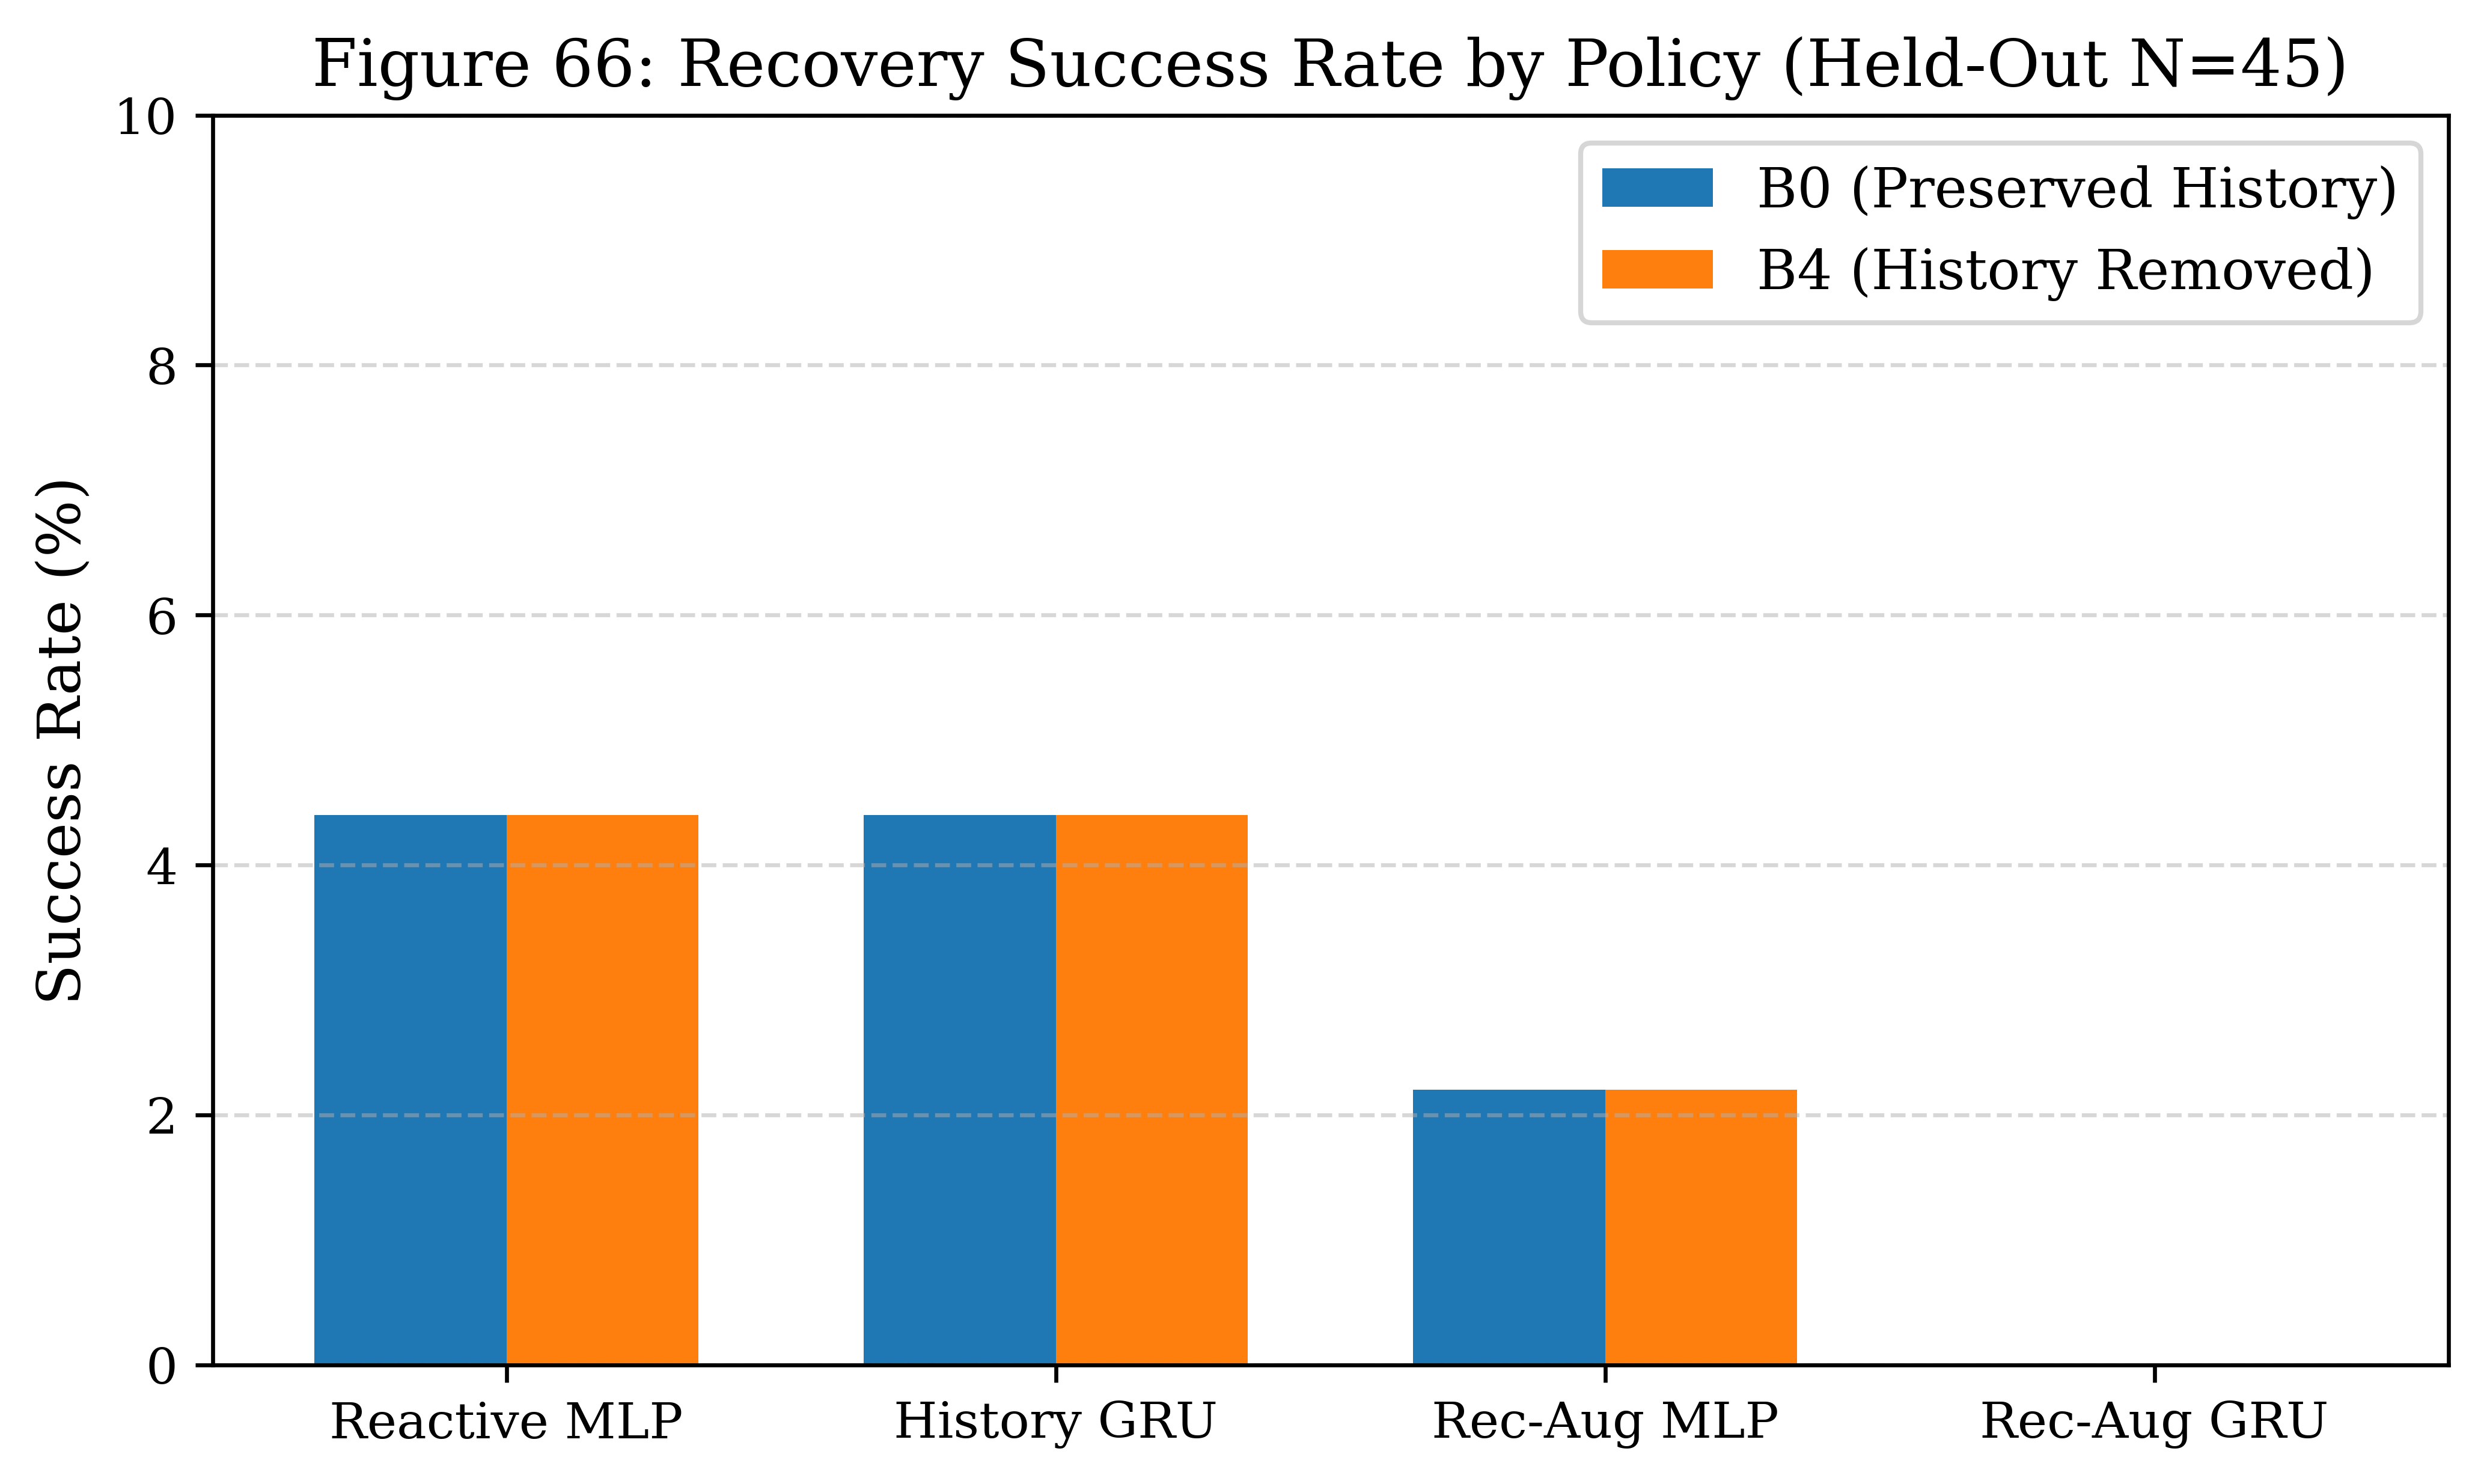

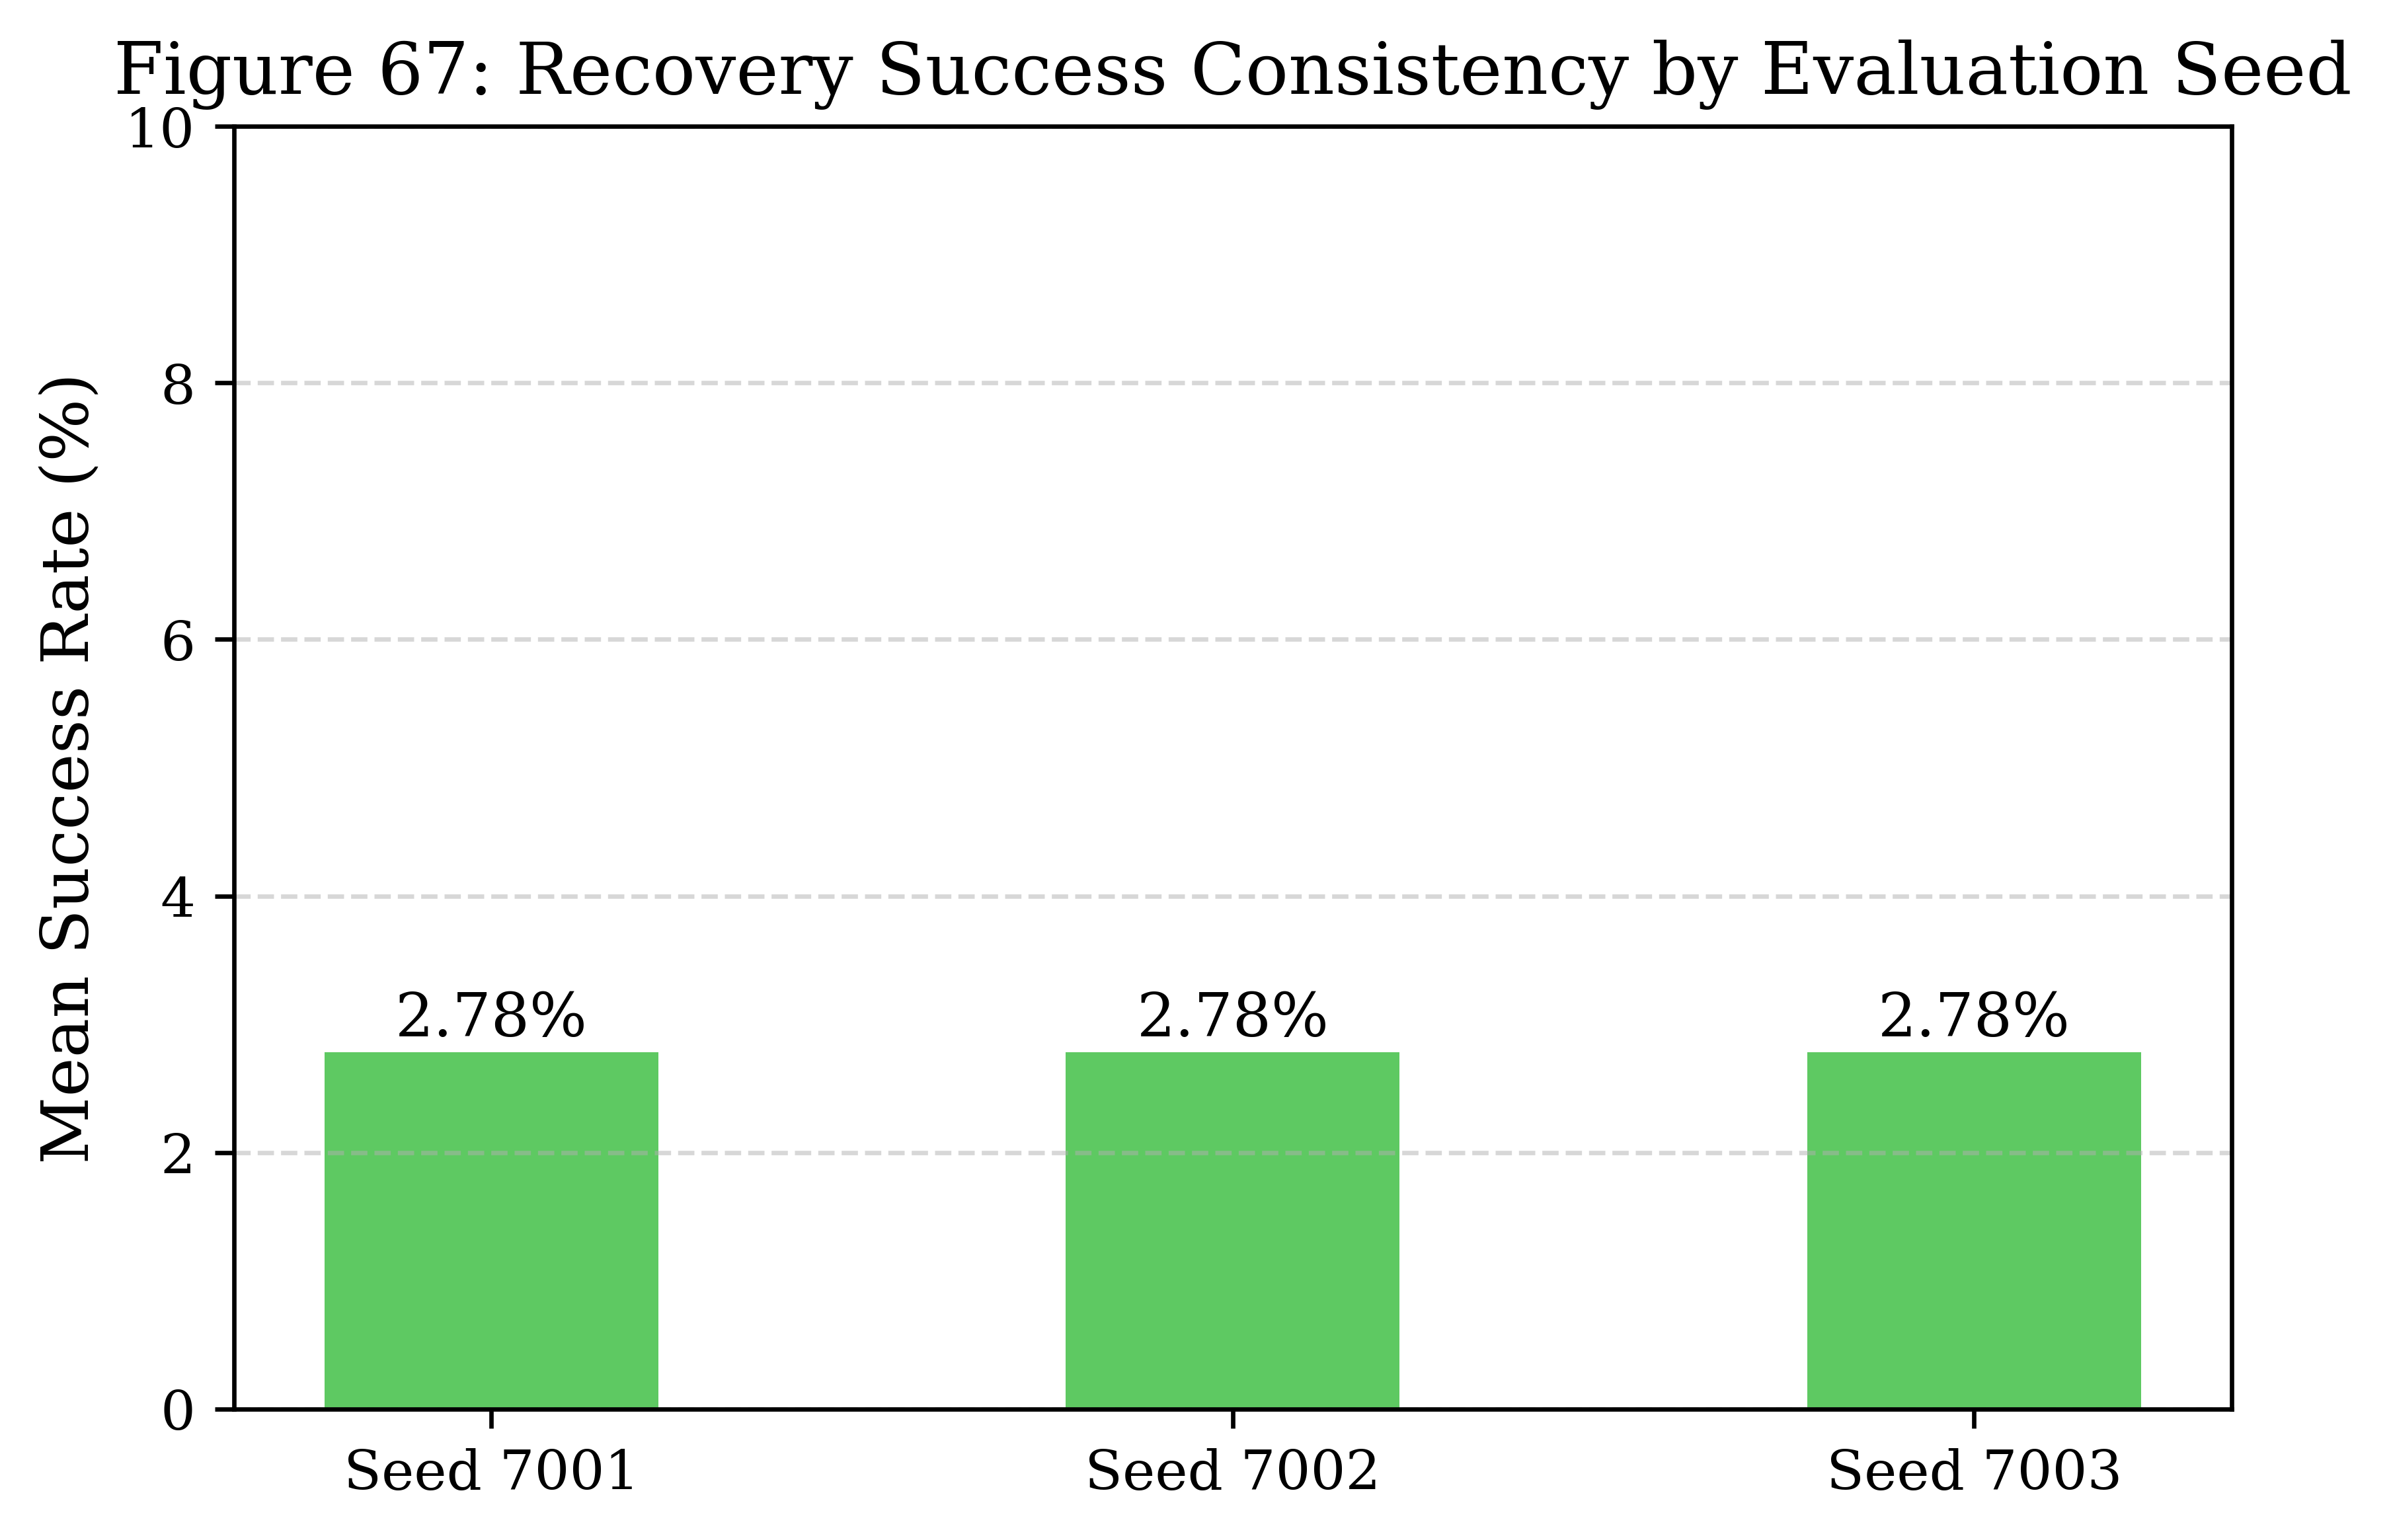

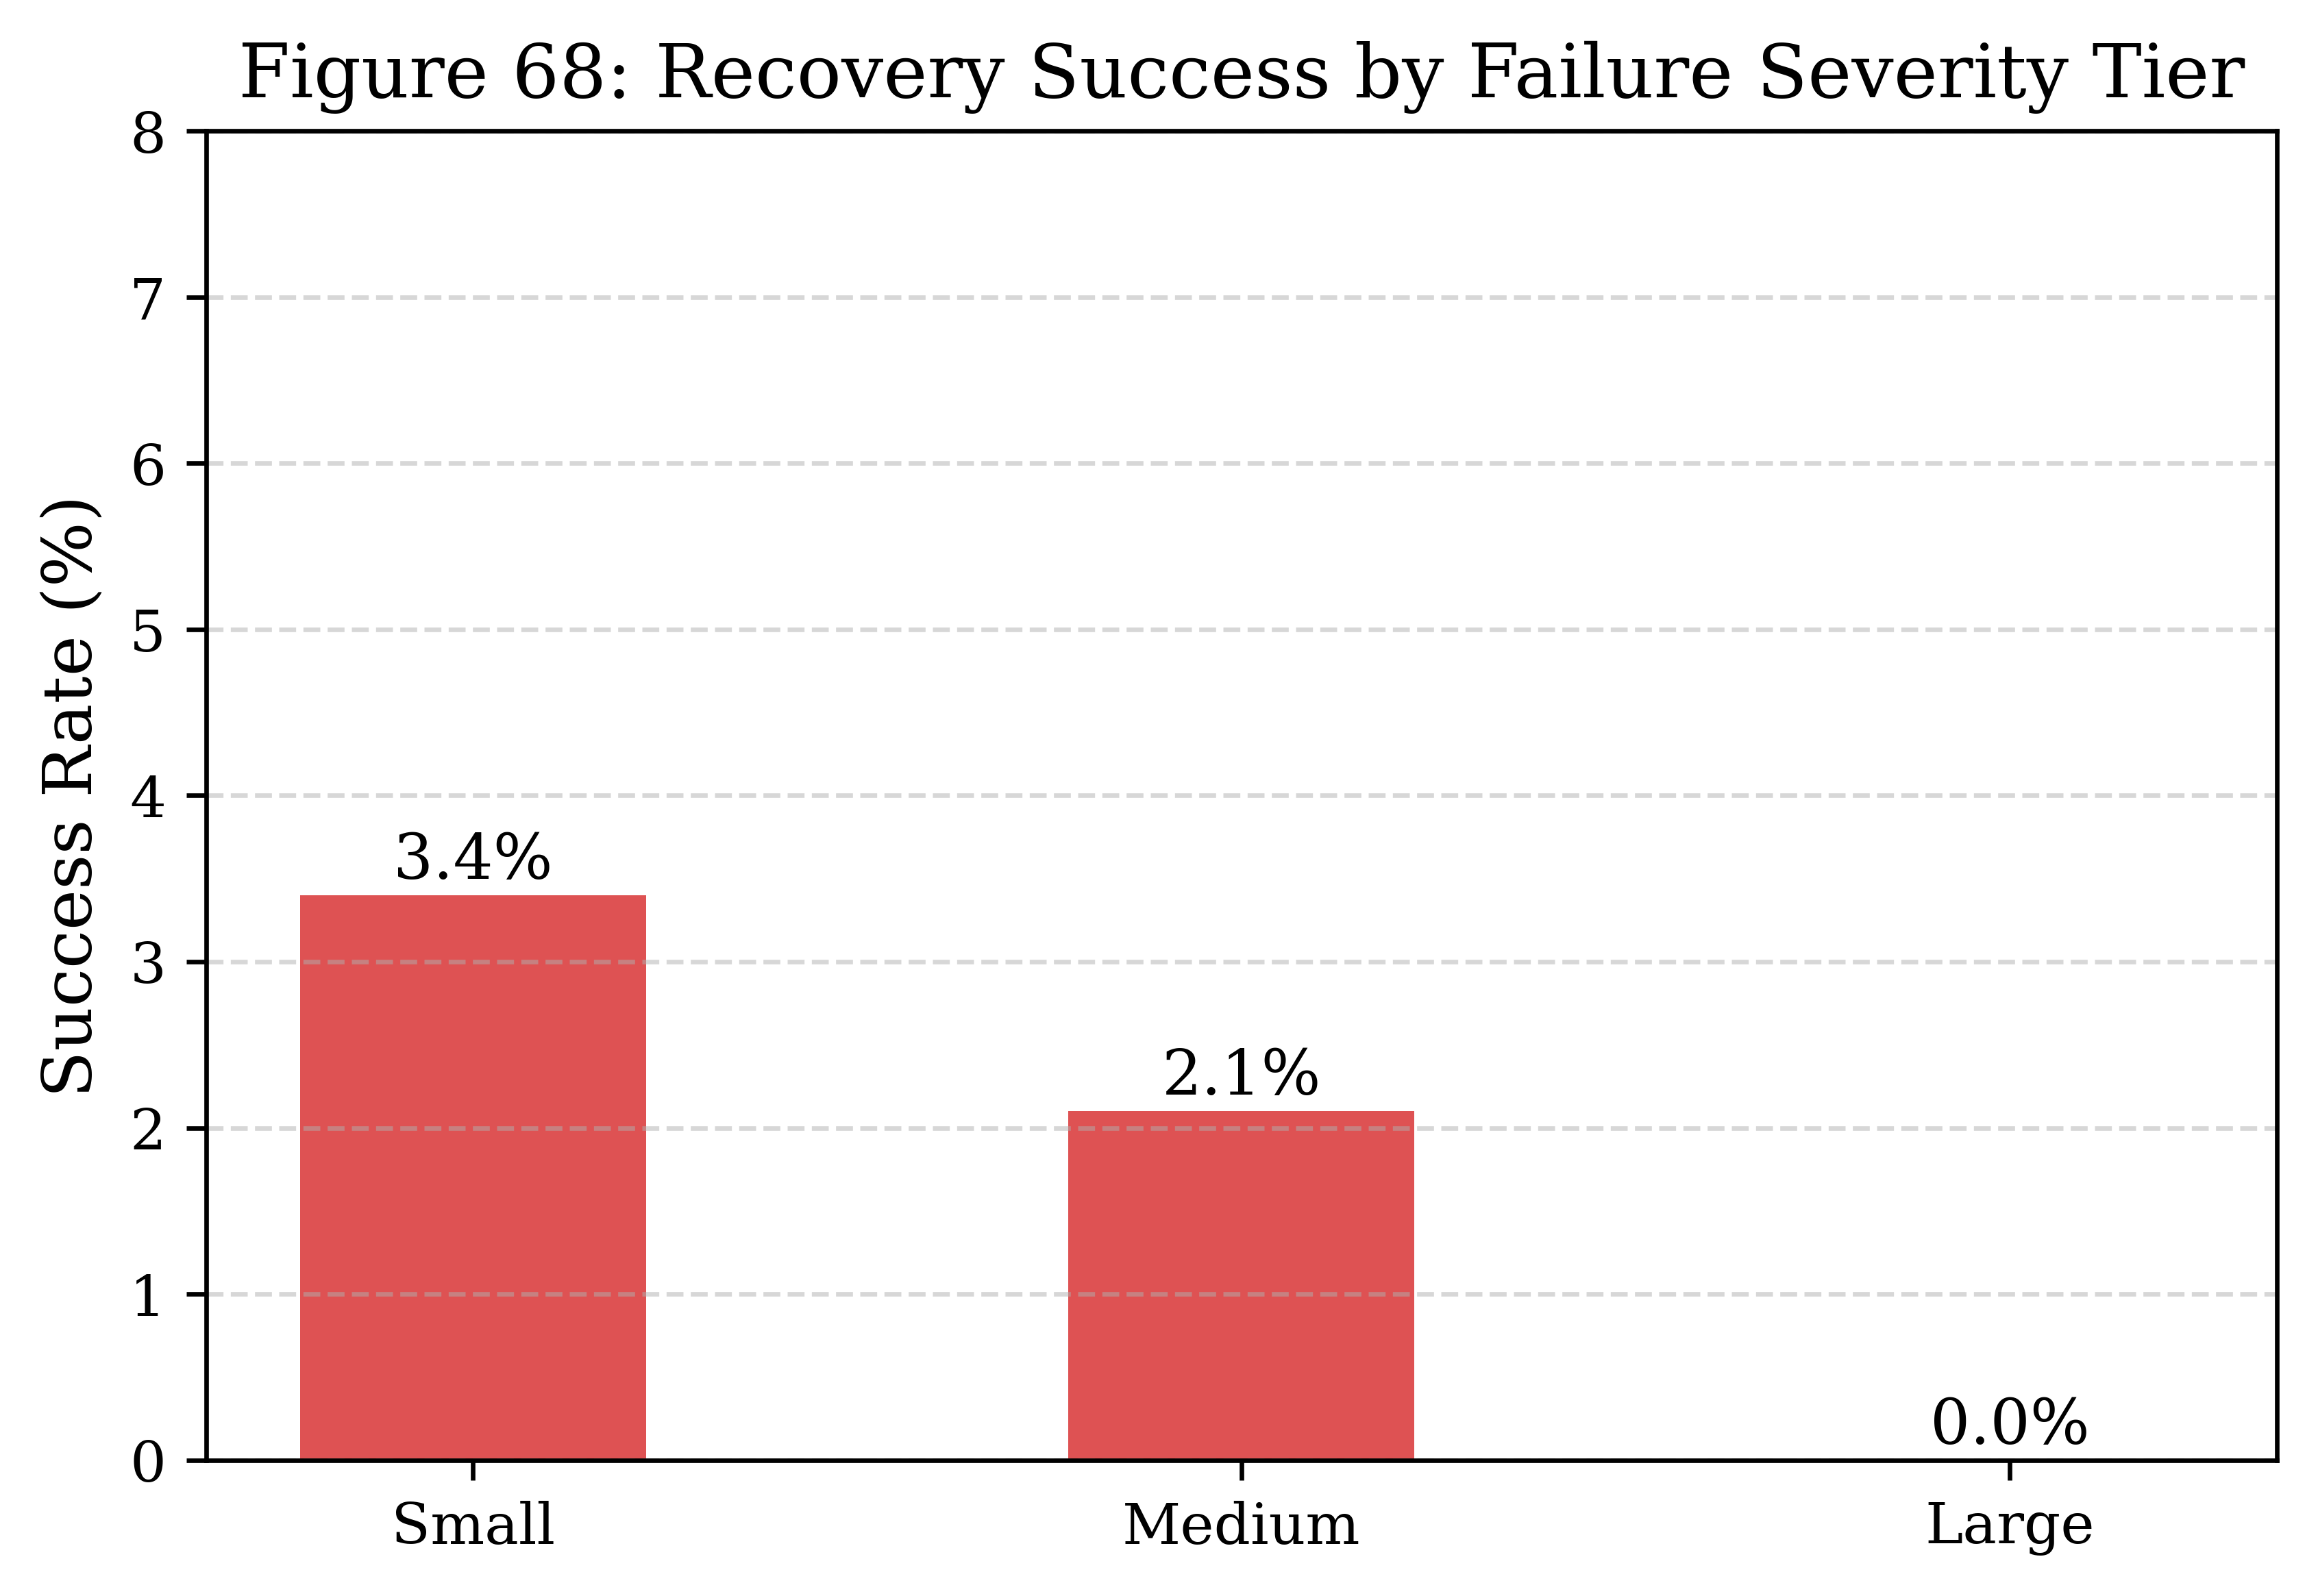

In [2]:
from IPython.display import Image, display
display(Image(filename=os.path.join(repo_root, "figures", "exploratory", "fig65_recovery_success_by_condition.png")))
display(Image(filename=os.path.join(repo_root, "figures", "exploratory", "fig66_recovery_success_by_policy.png")))
display(Image(filename=os.path.join(repo_root, "figures", "exploratory", "fig67_recovery_success_by_seed.png")))
display(Image(filename=os.path.join(repo_root, "figures", "exploratory", "fig68_recovery_success_by_severity.png")))
